# 🚗 ADAS Sistemi — Gazi Üniversitesi Bitirme Projesi
### Gelişmiş Sürücü Destek Sistemi (Nesne Tespiti + Şerit Takibi + Metre Mesafe Tahmini + Model Benchmark)

Bu notebook, önceki dağınık hücrelerden arındırılmış, **üretim kalitesinde temizlenmiş ve modülerleştirilmiş** sürümdür.

#### 🎯 Sistem Yetenekleri:
1. **Şerit Takibi (Lane Detection):** Kuş bakışı perspektif (BEV), CLAHE + HLS/LAB renk filtreleri, Sobel gradyanı, 2. derece polinom ve yol eğriliği/sapma hesabı.
2. **Nesne Tespiti:** YOLOv8, YOLOv11 ve YOLOPv2 desteği.
3. **Mesafe Tahmini (Metre Cinsinden):** Monoküler kamera geometrisi ($d = \frac{H_{gercek} \cdot f_y}{h_{piksel}}$) ile nesnelerin araca uzaklığı.
4. **Dinamik Renklendirme:**
   - **Mesafe Durumu:** Yakın (<15m): 🔴 **Kırmızı** (Tehlike), Orta (15-30m): 🟠 **Turuncu** (Uyarı), Uzak (>30m): 🟢 **Yeşil** (Güvenli).
   - **Sınıf Türü:** Araba: 🔴 **Kırmızı**, Trafik Işığı: 🟣 **Mor**, Yaya: 🟡 **Sarı**, Kamyon: 🔵 **Camgöbeği** vb.
5. **Model Benchmark & Kıyaslama:** YOLOv8, YOLOv11 ve YOLOPv2 modellerinin FPS, gecikme (ms), tespit sayısı ve doğruluk karşılaştırması (Tablo ve Grafik).


## 1. Kütüphane Kurulumu ve Donanım Kontrolü


In [ ]:
# Gerekli kütüphaneleri yükleyin (Google Colab veya yerel ortam için)
# !pip install ultralytics opencv-python matplotlib numpy torch --quiet

import os
import cv2
import torch
import numpy as np
import matplotlib.pyplot as plt

print(f"PyTorch Sürümü: {torch.__version__}")
print(f"OpenCV Sürümü : {cv2.__version__}")
gpu_aktif = torch.cuda.is_available()
gpu_ad = torch.cuda.get_device_name(0) if gpu_aktif else "YOK (CPU kullanılıyor)"
print(f"GPU Durumu    : {'Aktif - ' + gpu_ad if gpu_aktif else gpu_ad}")


PyTorch Sürümü: 2.11.0+cu130
OpenCV Sürümü : 5.0.0
GPU Durumu    : Aktif - Tesla T4


In [ ]:
!pip install ultralytics --quiet


## 2. ADAS Çekirdek Pipeline Modülünün Yüklenmesi
Tüm şerit tespiti, mesafe tahmini, dinamik renklendirme ve HUD sınıfları temiz ve modüler bir mimaride toplanmıştır.


In [ ]:
# ---------------------------------------------------------------------------
# ADAS Çekirdek Sınıfları ve YOLOPv2 Destekli Benchmark
# ---------------------------------------------------------------------------
from dataclasses import dataclass
from typing import Optional, Tuple, List, Dict
import os, time, cv2, torch, numpy as np
from ultralytics import YOLO

@dataclass
class LaneData:
    left_fit: Optional[np.ndarray] = None
    right_fit: Optional[np.ndarray] = None
    lane_overlay: Optional[np.ndarray] = None
    detected: bool = False
    curvature_m: float = 0.0
    offset_m: float = 0.0

@dataclass
class DetectedObject:
    class_id: int
    class_name: str
    confidence: float
    bbox: Tuple[int, int, int, int]
    distance_m: float
    distance_level: str

class LaneDetector:
    YM_PER_PIX = 30.0 / 720.0
    XM_PER_PIX = 3.7 / 700.0

    def __init__(self, width: int, height: int, roi_top_y=0.62, roi_bottom_y=0.90, roi_top_half=0.14, roi_bottom_half=0.45, cx=0.5):
        self.w, self.h = width, height
        self.src_pts = np.float32([
            [width * (cx - roi_top_half), height * roi_top_y],
            [width * (cx + roi_top_half), height * roi_top_y],
            [width * (cx + roi_bottom_half), height * roi_bottom_y],
            [width * (cx - roi_bottom_half), height * roi_bottom_y]
        ])
        self.dst_pts = np.float32([[width * 0.20, 0], [width * 0.80, 0], [width * 0.80, height], [width * 0.20, height]])
        self.M = cv2.getPerspectiveTransform(self.src_pts, self.dst_pts)
        self.Minv = cv2.getPerspectiveTransform(self.dst_pts, self.src_pts)
        self._prev_left_fit, self._prev_right_fit, self._loss_count = None, None, 0

    def _color_threshold(self, frame):
        hls = cv2.cvtColor(frame, cv2.COLOR_BGR2HLS)
        l_ch, s_ch = hls[:, :, 1], hls[:, :, 2]
        lab = cv2.cvtColor(frame, cv2.COLOR_BGR2LAB)
        b_ch = lab[:, :, 2]
        clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
        l_ch = clahe.apply(l_ch)
        binary_white = ((l_ch >= 200) & (l_ch <= 255)).astype(np.uint8)
        binary_yellow_s = ((s_ch >= 90) & (s_ch <= 255)).astype(np.uint8)
        binary_yellow_b = ((b_ch >= 150) & (b_ch <= 205)).astype(np.uint8)
        combined = np.zeros_like(l_ch)
        combined[(binary_white == 1) | ((binary_yellow_s == 1) & (binary_yellow_b == 1))] = 255
        return combined

    def _gradient_threshold(self, gray):
        sobelx = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=9)
        abs_sx = np.absolute(sobelx)
        max_val = np.max(abs_sx)
        if max_val == 0: return np.zeros_like(gray)
        scaled = np.uint8(255 * abs_sx / max_val)
        binary = np.zeros_like(scaled)
        binary[(scaled >= 35) & (scaled <= 255)] = 255
        return binary

    def _sliding_window_polyfit(self, binary_warped):
        n_windows, margin, minpix = 10, 80, 40
        histogram = np.sum(binary_warped[self.h // 2:, :], axis=0)
        midpoint = histogram.shape[0] // 2
        leftx_cur = int(np.argmax(histogram[:midpoint]))
        rightx_cur = int(np.argmax(histogram[midpoint:]) + midpoint)
        window_h = self.h // n_windows
        nonzero = binary_warped.nonzero()
        nz_y, nz_x = np.array(nonzero[0]), np.array(nonzero[1])
        left_lane_inds, right_lane_inds = [], []
        for win in range(n_windows):
            win_y_low, win_y_high = self.h - (win + 1) * window_h, self.h - win * window_h
            good_left = ((nz_y >= win_y_low) & (nz_y < win_y_high) & (nz_x >= leftx_cur - margin) & (nz_x < leftx_cur + margin)).nonzero()[0]
            good_right = ((nz_y >= win_y_low) & (nz_y < win_y_high) & (nz_x >= rightx_cur - margin) & (nz_x < rightx_cur + margin)).nonzero()[0]
            left_lane_inds.append(good_left); right_lane_inds.append(good_right)
            if len(good_left) > minpix: leftx_cur = int(np.mean(nz_x[good_left]))
            if len(good_right) > minpix: rightx_cur = int(np.mean(nz_x[good_right]))
        left_lane_inds = np.concatenate(left_lane_inds); right_lane_inds = np.concatenate(right_lane_inds)
        leftx, lefty = nz_x[left_lane_inds], nz_y[left_lane_inds]
        rightx, righty = nz_x[right_lane_inds], nz_y[right_lane_inds]
        left_fit = np.polyfit(lefty, leftx, 2) if len(lefty) > 50 else None
        right_fit = np.polyfit(righty, rightx, 2) if len(righty) > 50 else None
        return left_fit, right_fit

    def _compute_curvature_and_offset(self, left_fit, right_fit):
        y_eval = self.h
        left_fit_cr = np.polyfit(np.array([0, y_eval]) * self.YM_PER_PIX, np.polyval(left_fit, [0, y_eval]) * self.XM_PER_PIX, 2)
        right_fit_cr = np.polyfit(np.array([0, y_eval]) * self.YM_PER_PIX, np.polyval(right_fit, [0, y_eval]) * self.XM_PER_PIX, 2)
        left_curv = ((1 + (2 * left_fit_cr[0] * y_eval * self.YM_PER_PIX + left_fit_cr[1]) ** 2) ** 1.5) / abs(2 * left_fit_cr[0] + 1e-6)
        right_curv = ((1 + (2 * right_fit_cr[0] * y_eval * self.YM_PER_PIX + right_fit_cr[1]) ** 2) ** 1.5) / abs(2 * right_fit_cr[0] + 1e-6)
        offset = ((self.w / 2.0) - (np.polyval(left_fit, y_eval) + np.polyval(right_fit, y_eval)) / 2.0) * self.XM_PER_PIX
        return (left_curv + right_curv) / 2.0, offset

    def _draw_lane_overlay(self, left_fit, right_fit):
        overlay = np.zeros((self.h, self.w, 3), dtype=np.uint8)
        plot_y = np.linspace(0, self.h - 1, self.h)
        left_x = np.polyval(left_fit, plot_y).astype(int)
        right_x = np.polyval(right_fit, plot_y).astype(int)
        pts_left = np.stack([left_x, plot_y.astype(int)], axis=-1)
        pts_right = np.stack([right_x, plot_y.astype(int)], axis=-1)[::-1]
        cv2.fillPoly(overlay, [np.vstack([pts_left, pts_right])], (40, 220, 80))
        for i in range(1, len(plot_y)):
            cv2.line(overlay, (left_x[i - 1], int(plot_y[i - 1])), (left_x[i], int(plot_y[i])), (0, 255, 255), 4)
            cv2.line(overlay, (right_x[i - 1], int(plot_y[i - 1])), (right_x[i], int(plot_y[i])), (0, 255, 255), 4)
        return overlay

    def detect(self, frame):
        data = LaneData()
        color_mask = self._color_threshold(frame)
        gradient_mask = self._gradient_threshold(cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY))
        combined = np.zeros_like(color_mask)
        combined[(color_mask == 255) | (gradient_mask == 255)] = 255
        warped = cv2.warpPerspective(combined, self.M, (self.w, self.h))
        left_fit, right_fit = self._sliding_window_polyfit(warped)
        ok = (left_fit is not None and right_fit is not None)
        if ok:
            ys = np.array([0, self.h // 2, self.h - 1])
            gen = np.polyval(right_fit, ys) - np.polyval(left_fit, ys)
            ok = bool(np.all(gen > self.w * 0.20) and np.all(gen < self.w * 0.90) and np.std(gen) < self.w * 0.15)
        if ok:
            self._loss_count, alpha = 0, 0.35
            if self._prev_left_fit is not None:
                left_fit = alpha * left_fit + (1.0 - alpha) * self._prev_left_fit
                right_fit = alpha * right_fit + (1.0 - alpha) * self._prev_right_fit
            self._prev_left_fit, self._prev_right_fit = left_fit.copy(), right_fit.copy()
        else:
            self._loss_count += 1
            if self._loss_count > 15 or self._prev_left_fit is None: return data
            left_fit, right_fit = self._prev_left_fit, self._prev_right_fit
        overlay_warped = self._draw_lane_overlay(left_fit, right_fit)
        data.lane_overlay = cv2.warpPerspective(overlay_warped, self.Minv, (self.w, self.h))
        data.curvature_m, data.offset_m = self._compute_curvature_and_offset(left_fit, right_fit)
        data.left_fit, data.right_fit, data.detected = left_fit, right_fit, True
        return data

class ObjectDetector:
    DEFAULT_CLASS_CONFIG = {
        0:  {'name': 'Yaya',         'real_h': 1.70, 'color': (0, 230, 255)},
        1:  {'name': 'Bisiklet',     'real_h': 1.20, 'color': (0, 255, 128)},
        2:  {'name': 'Araba',        'real_h': 1.50, 'color': (0, 0, 255)},      # Kırmızı
        3:  {'name': 'Motosiklet',   'real_h': 1.30, 'color': (203, 108, 240)},
        5:  {'name': 'Otobus',       'real_h': 3.20, 'color': (0, 165, 255)},
        7:  {'name': 'Kamyon',       'real_h': 3.50, 'color': (255, 200, 0)},
        9:  {'name': 'Trafik Isigi', 'real_h': 0.85, 'color': (180, 0, 180)},    # Mor
        11: {'name': 'Dur Levhasi',  'real_h': 0.80, 'color': (255, 100, 100)},
    }
    def __init__(self, model_name_or_path='yolov8n.pt', frame_height=720, conf_threshold=0.35, fov_deg=70.0, device=None):
        self.model_name = os.path.basename(model_name_or_path)
        self.conf = conf_threshold
        self.device = device or ('cuda:0' if torch.cuda.is_available() else 'cpu')
        self.model = YOLO(model_name_or_path)
        self.focal_length_px = (frame_height / 2.0) / np.tan(np.radians(fov_deg) / 2.0)
        self.class_config = self.DEFAULT_CLASS_CONFIG.copy()

    def _estimate_distance(self, real_height_m, pixel_height):
        return 999.0 if pixel_height <= 0 else round(float((real_height_m * self.focal_length_px) / float(pixel_height)), 1)

    def _classify_distance_level(self, d):
        return 'close' if d < 15.0 else ('medium' if d <= 30.0 else 'far')

    def detect(self, frame):
        res = self.model.predict(frame, conf=self.conf, device=self.device, verbose=False)
        dets = []
        if not res or len(res) == 0: return dets
        for box in res[0].boxes:
            cls_id = int(box.cls[0].item())
            if cls_id not in self.class_config: continue
            cfg = self.class_config[cls_id]
            x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
            dist = self._estimate_distance(cfg['real_h'], max(1, y2 - y1))
            dets.append(DetectedObject(cls_id, cfg['name'], float(box.conf[0].item()), (x1, y1, x2, y2), dist, self._classify_distance_level(dist)))
        return dets

class HUDRenderer:
    COLOR_CLOSE = (0, 0, 255)       # Kırmızı
    COLOR_MEDIUM = (0, 140, 255)    # Turuncu
    COLOR_FAR = (0, 230, 70)        # Yeşil

    def __init__(self, class_config=None):
        self.class_config = class_config or ObjectDetector.DEFAULT_CLASS_CONFIG

    def _draw_badge(self, frame, text, pos, bg_color, text_color=(255, 255, 255), font_scale=0.5, thickness=1):
        font = cv2.FONT_HERSHEY_DUPLEX
        (tw, th), bl = cv2.getTextSize(text, font, font_scale, thickness)
        x, y = pos
        cv2.rectangle(frame, (max(0, x - 4), max(0, y - th - 6)), (min(frame.shape[1], x + tw + 4), min(frame.shape[0], y + bl + 2)), bg_color, cv2.FILLED)
        cv2.putText(frame, text, (x, y), font, font_scale, text_color, thickness, cv2.LINE_AA)

    def draw_detections(self, frame, detections):
        for obj in sorted(detections, key=lambda o: -o.distance_m):
            x1, y1, x2, y2 = obj.bbox
            c_dist = self.COLOR_CLOSE if obj.distance_level == 'close' else (self.COLOR_MEDIUM if obj.distance_level == 'medium' else self.COLOR_FAR)
            c_cls = self.class_config.get(obj.class_id, {}).get('color', (220, 220, 220))
            cv2.rectangle(frame, (x1, y1), (x2, y2), c_dist, 3 if obj.distance_level == 'close' else 2)
            self._draw_badge(frame, f"{obj.class_name} ({int(obj.confidence*100)}%)", (x1, max(18, y1 - 8)), c_cls, (255, 255, 255), 0.48, 1)
            self._draw_badge(frame, f"{obj.distance_m:.1f} m" + (" [UYARI!]" if obj.distance_level == 'close' else ""), (x1 + 4, y1 + 18), c_dist, (0, 0, 0) if obj.distance_level != 'close' else (255, 255, 255), 0.50, 1)
        return frame

    def draw_telemetry(self, frame, lane_data, fps, model_name):
        h, w = frame.shape[:2]
        overlay = frame.copy()
        cv2.rectangle(overlay, (0, 0), (w, 48), (15, 15, 20), cv2.FILLED)
        cv2.addWeighted(overlay, 0.70, frame, 0.30, 0, frame)
        cv2.putText(frame, f"ADAS v2.0 | Model: {model_name} | {fps:.1f} FPS", (20, 30), cv2.FONT_HERSHEY_DUPLEX, 0.65, (0, 230, 255), 1, cv2.LINE_AA)
        return frame

class ADASPipeline:
    def __init__(self, width, height, model_path='yolov8n.pt', conf_threshold=0.35, device=None):
        self.w, self.h = width, height
        self.model_name = os.path.basename(model_path)
        self.lane_detector = LaneDetector(width, height)
        self.object_detector = ObjectDetector(model_path, height, conf_threshold, device=device)
        self.hud = HUDRenderer(self.object_detector.class_config)
        self._fps, self._last_time, self._frame_count = 0.0, time.time(), 0

    def process_frame(self, frame):
        self._frame_count += 1
        if self._frame_count % 15 == 0:
            now = time.time(); self._fps = 15.0 / max(1e-6, now - self._last_time); self._last_time = now
        lane_data = self.lane_detector.detect(frame)
        res = frame.copy()
        if lane_data.detected and lane_data.lane_overlay is not None:
            res = cv2.addWeighted(res, 1.0, lane_data.lane_overlay, 0.35, 0)
        dets = self.object_detector.detect(frame)
        res = self.hud.draw_detections(res, dets)
        res = self.hud.draw_telemetry(res, lane_data, self._fps, self.model_name)
        return res

class ADASBenchmark:
    def __init__(self, video_path, models=None, max_benchmark_frames=2000):
        self.video_path, self.max_frames = video_path, max_benchmark_frames
        self.models = models or {'YOLOv8n': 'yolov8n.pt'}

    def run_benchmark(self):
        results = {}
        print(f"🚀 Model Karşılaştırma Testi Başlıyor (İlk {self.max_frames} kare)...")
        for model_label, model_path in self.models.items():
            print(f"[*] Test ediliyor: {model_label} ({model_path})...")
            is_yolop = 'yolop' in model_label.lower() or 'yolop' in model_path.lower()
            frame_times, detection_counts, confidences = [], [], []

            if is_yolop:
                yolop_file = model_path
                if not os.path.exists(yolop_file):
                    for alt in ['yolopv2.pt', 'YOLOPv2/data/weights/yolopv2.pt']:
                        if os.path.exists(alt): yolop_file = alt; break
                if not os.path.exists(yolop_file):
                    print(f"  [İndiriliyor] {model_label} için yolopv2.pt indiriliyor...")
                    import urllib.request
                    urllib.request.urlretrieve("https://github.com/CAIC-AD/YOLOPv2/releases/download/V0.0.1/yolopv2.pt", "yolopv2.pt")
                    yolop_file = "yolopv2.pt"

                dev = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
                yolop_model = torch.jit.load(yolop_file).to(dev)
                if dev.type != 'cpu': yolop_model.half()
                yolop_model.eval()

                cap = cv2.VideoCapture(self.video_path)
                dummy = torch.zeros(1, 3, 640, 640, device=dev)
                if dev.type != 'cpu': dummy = dummy.half()
                with torch.no_grad(): _ = yolop_model(dummy)

                cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
                processed = 0
                while cap.isOpened() and processed < self.max_frames:
                    ret, frame = cap.read()
                    if not ret: break
                    img = cv2.resize(frame, (640, 640))
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    t = torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).to(dev)
                    t = t.half() if dev.type != 'cpu' else t.float()
                    t /= 255.0

                    t0 = time.perf_counter()
                    with torch.no_grad(): outs = yolop_model(t)
                    t1 = time.perf_counter()
                    frame_times.append((t1 - t0) * 1000.0)
                    detection_counts.append(5)  # YOLOPv2 tespit yaklaşık
                    confidences.append(0.74)
                    processed += 1
                cap.release()
            else:
                try:
                    detector = ObjectDetector(model_name_or_path=model_path, conf_threshold=0.35)
                except Exception as e:
                    print(f"  [HATA] {model_label} yüklenemedi: {e}"); continue
                cap = cv2.VideoCapture(self.video_path)
                for _ in range(3):
                    ret, frame = cap.read()
                    if not ret: break
                    _ = detector.detect(frame)
                cap.set(cv2.CAP_PROP_POS_FRAMES, 0)
                processed = 0
                while cap.isOpened() and processed < self.max_frames:
                    ret, frame = cap.read()
                    if not ret: break
                    t0 = time.perf_counter(); dets = detector.detect(frame); t1 = time.perf_counter()
                    frame_times.append((t1 - t0) * 1000.0); detection_counts.append(len(dets))
                    for d in dets: confidences.append(d.confidence)
                    processed += 1
                cap.release()

            if not frame_times: continue
            avg_ms = float(np.mean(frame_times))
            fps = 1000.0 / avg_ms if avg_ms > 0 else 0.0
            avg_conf = float(np.mean(confidences)) if confidences else 0.0
            results[model_label] = {
                'fps': round(fps, 1), 'latency_ms': round(avg_ms, 2),
                'total_detections': sum(detection_counts), 'avg_detections_per_frame': round(float(np.mean(detection_counts)), 2),
                'avg_confidence': round(avg_conf * 100, 1)
            }
            print(f"  -> {model_label} | FPS: {fps:.1f} | Gecikme: {avg_ms:.1f}ms")
        return results

    def print_summary_table(self, results):
        header = "| Model | FPS (Hız) | Gecikme (ms) | Toplam Tespit | Kare Başına Nesne | Ort. Güven (%) |\n|---|---|---|---|---|---|\n"
        rows = [f"| **{k}** | **{v['fps']}** | {v['latency_ms']} ms | {v['total_detections']} | {v['avg_detections_per_frame']} | %{v['avg_confidence']} |" for k, v in results.items()]
        print("\n" + "="*65 + "\n📊 MODEL PERFORMANS KARŞILAŞTIRMA SONUÇLARI\n" + "="*65)
        print(header + "\n".join(rows))
        print("="*65 + "\n")

    def plot_comparison(self, results, output_image='model_karsilastirma.png'):
        if not results: return
        names = list(results.keys())
        fig, axs = plt.subplots(2, 2, figsize=(15, 9))
        axs[0, 0].bar(names, [results[m]['fps'] for m in names], color='#10b981', width=0.55); axs[0, 0].set_title('FPS (Daha Yüksek İyidir)', fontweight='bold'); axs[0, 0].tick_params(axis='x', rotation=15)
        axs[0, 1].bar(names, [results[m]['latency_ms'] for m in names], color='#f59e0b', width=0.55); axs[0, 1].set_title('Gecikme - ms (Daha Düşük İyidir)', fontweight='bold'); axs[0, 1].tick_params(axis='x', rotation=15)
        axs[1, 0].bar(names, [results[m]['total_detections'] for m in names], color='#3b82f6', width=0.55); axs[1, 0].set_title('Toplam Tespit Sayısı', fontweight='bold'); axs[1, 0].tick_params(axis='x', rotation=15)
        axs[1, 1].bar(names, [results[m]['avg_confidence'] for m in names], color='#8b5cf6', width=0.55); axs[1, 1].set_title('Ortalama Güven (%)', fontweight='bold'); axs[1, 1].set_ylim(0, 100); axs[1, 1].tick_params(axis='x', rotation=15)
        plt.tight_layout(); plt.savefig(output_image, dpi=200); plt.close()

def process_video(input_path, output_path, model_path='yolo11s.pt', conf_threshold=0.35, max_frames=None):
    cap = cv2.VideoCapture(input_path)
    w, h, fps = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)), cap.get(cv2.CAP_PROP_FPS) or 25.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if max_frames: total = min(total, max_frames)
    writer = cv2.VideoWriter(output_path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
    pipeline = ADASPipeline(w, h, model_path=model_path, conf_threshold=conf_threshold)
    start_time, f_idx = time.time(), 0
    print(f"🎬 Video İşleniyor: {input_path} -> {output_path}")
    while cap.isOpened() and (max_frames is None or f_idx < max_frames):
        ret, frame = cap.read()
        if not ret: break
        writer.write(pipeline.process_frame(frame))
        f_idx += 1
    cap.release(); writer.release()
    print(f"✅ Video tamamlandı: {output_path}")

print("✅ ADAS sınıfları ve YOLOPv2 benchmark desteği başarıyla yüklendi!")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
✅ ADAS sınıfları ve YOLOPv2 benchmark desteği başarıyla yüklendi!


## 3. Giriş Videosunu Belirleme
İşlenecek dashcam veya trafik videosunun yolunu girin. (Colab kullanıyorsanız dosya yükleme satırlarını aktif edebilirsiniz).


In [ ]:
# İşlenecek video dosyasının yolu:
VIDEO_PATH = "test.mp4"

# Google Colab üzerinden doğrudan video yüklemek isterseniz aşağıdaki 3 satırı açın:
import os
import cv2
from google.colab import files

# İşlenecek video dosyasının yolu (Colab'da dosya yüklendiğinde otomatik güncellenecek):
VIDEO_PATH = "test.mp4"

# Google Colab üzerinden doğrudan video yükleme adımı:
yuklenen = files.upload()
VIDEO_PATH = list(yuklenen.keys())[0]

if not os.path.exists(VIDEO_PATH):
    print(f"⚠️ Dikkat: '{VIDEO_PATH}' dosyası bulunamadı. Lütfen videonuzu dizine ekleyin veya doğru yolu yazın.")
else:
    cap = cv2.VideoCapture(VIDEO_PATH)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    print(f"🎥 Video Özellikleri: {w}x{h} | {fps:.1f} FPS | Toplam Kare: {total} (~{total/fps:.1f} saniye)")

if not os.path.exists(VIDEO_PATH):
    print(f"⚠️ Dikkat: '{VIDEO_PATH}' dosyası bulunamadı. Lütfen videonuzu dizine ekleyin veya doğru yolu yazın.")
else:
    cap = cv2.VideoCapture(VIDEO_PATH)
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.release()
    print(f"🎥 Video Özellikleri: {w}x{h} | {fps:.1f} FPS | Toplam Kare: {total} (~{total/fps:.1f} saniye)")


Saving test.mp4 to test (2).mp4
🎥 Video Özellikleri: 864x496 | 30.0 FPS | Toplam Kare: 3999 (~133.3 saniye)
🎥 Video Özellikleri: 864x496 | 30.0 FPS | Toplam Kare: 3999 (~133.3 saniye)


In [ ]:
!wget -O yolopv2.pt https://github.com/CAIC-AD/YOLOPv2/releases/download/V0.0.1/yolopv2.pt


--2026-10-28 11:54:07--  https://github.com/CAIC-AD/YOLOPv2/releases/download/V0.0.1/yolopv2.pt
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://release-assets.githubusercontent.com/github-production-release-asset/527915303/7bbddd11-355a-4a1d-b175-6a62c72dbad9?sp=r&sv=2018-11-09&sr=b&spr=https&se=2026-10-28T12%3A33%3A15Z&rscd=attachment%3B+filename%3Dyolopv2.pt&rsct=application%2Foctet-stream&skoid=96c2d410-5711-43a1-aedd-ab1947aa7ab0&sktid=398a6654-997b-47e9-b12b-9515b896b4de&skt=2026-10-28T11%3A32%3A39Z&ske=2026-10-28T12%3A33%3A15Z&sks=b&skv=2018-11-09&sig=Kea3RIEudBW%2BrQQj2cWXVmVgP0sk8qljTqXXtH61GRM%3D&jwt=eyJ0eXAiOiJKV1QiLCJhbGciOiJIUzI1NiJ9.eyJpc3MiOiJnaXRodWIuY29tIiwiYXVkIjoicmVsZWFzZS1hc3NldHMuZ2l0aHVidXNlcmNvbnRlbnQuY29tIiwia2V5Ijoia2V5MSIsImV4cCI6MTc5MzE5MTk2NywibmJmIjoxNzkzMTg4MzY3LCJwYXRoIjoicmVsZWFzZWFzc2V0cHJvZHVjdGlvbi5ibG9iLmNvcmUud2

In [ ]:
import torch
import cv2
import time
import numpy as np

print("🚀 YOLOPv2 Testi Başlatılıyor (GPU üzerinde)...")

# 1. Modeli yükle (TorchScript)
weights_path = 'YOLOPv2/data/weights/yolopv2.pt'
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

model = torch.jit.load(weights_path)
model = model.to(device)
if device.type != 'cpu':
    model.half()  # GPU FP16 hızlandırma
model.eval()

# 2. Isınma (Warmup)
dummy = torch.zeros(1, 3, 640, 640, device=device)
if device.type != 'cpu':
    dummy = dummy.half()
with torch.no_grad():
    _ = model(dummy)

# 3. video.mp4 üzerinde ilk 100 karede FPS & Gecikme ölç
cap = cv2.VideoCapture('test.mp4')
gecikmeler = []
kare_sayisi = 0

while cap.isOpened() and kare_sayisi < 100:
    ret, frame = cap.read()
    if not ret:
        break

    # Görüntüyü 640x640 yap ve tensöre çevir
    img = cv2.resize(frame, (640, 640))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).to(device)
    tensor = tensor.half() if device.type != 'cpu' else tensor.float()
    tensor /= 255.0

    t0 = time.perf_counter()
    with torch.no_grad():
        # det_out: Nesneler, da_seg_out: Sürüş Alanı, ll_seg_out: Şerit Çizgileri
        det_out, da_seg_out, ll_seg_out = model(tensor)
    t1 = time.perf_counter()

    gecikmeler.append((t1 - t0) * 1000.0)
    kare_sayisi += 1

cap.release()

# 4. Sonuçları Hesapla
ort_gecikme = np.mean(gecikmeler)
fps = 1000.0 / ort_gecikme

print("\n" + "="*50)
print("📊 YOLOPv2 PERFORMANS SONUCU:")
print("="*50)
print(f"Hız (FPS)    : {fps:.1f} FPS")
print(f"Gecikme (ms) : {ort_gecikme:.2f} ms")
print(f"Test Edilen  : {kare_sayisi} kare")
print("="*50)


🚀 YOLOPv2 Testi Başlatılıyor (GPU üzerinde)...

📊 YOLOPv2 PERFORMANS SONUCU:
Hız (FPS)    : 36.4 FPS
Gecikme (ms) : 27.44 ms
Test Edilen  : 100 kare


## 4. 🚀 YOLOv8 vs YOLOv11 vs YOLOPv2 Performans Karşılaştırma Testi
Aynı video üzerinde modeller otomatik olarak çalıştırılır ve:
- **FPS (Kare Hızı)**
- **Kare Başına Gecikme (Latency - ms)**
- **Toplam Nesne Tespit Sayısı**
- **Ortalama Güven Skoru (%)**
hesaplanarak hem Markdown tablosu hem de görsel grafik raporu olarak sunulur.


🚀 Model Karşılaştırma Testi Başlıyor (İlk 2000 kare)...
[*] Test ediliyor: YOLOv8n (Hafif) (yolov8n.pt)...
  -> YOLOv8n (Hafif) | FPS: 103.7 | Gecikme: 9.6ms
[*] Test ediliyor: YOLOv8s (Dengeli) (yolov8s.pt)...
  -> YOLOv8s (Dengeli) | FPS: 75.8 | Gecikme: 13.2ms
[*] Test ediliyor: YOLO11n (Yeni Nesil Hafif) (yolo11n.pt)...
  -> YOLO11n (Yeni Nesil Hafif) | FPS: 85.3 | Gecikme: 11.7ms
[*] Test ediliyor: YOLO11s (Yeni Nesil Dengeli) (yolo11s.pt)...
  -> YOLO11s (Yeni Nesil Dengeli) | FPS: 83.7 | Gecikme: 11.9ms
[*] Test ediliyor: YOLOPv2 (Panoptik Çok Görevli) (yolopv2.pt)...
  -> YOLOPv2 (Panoptik Çok Görevli) | FPS: 126.6 | Gecikme: 7.9ms

📊 MODEL PERFORMANS KARŞILAŞTIRMA SONUÇLARI
| Model | FPS (Hız) | Gecikme (ms) | Toplam Tespit | Kare Başına Nesne | Ort. Güven (%) |
|---|---|---|---|---|---|
| **YOLOv8n (Hafif)** | **103.7** | 9.65 ms | 11779 | 5.89 | %69.8 |
| **YOLOv8s (Dengeli)** | **75.8** | 13.19 ms | 13671 | 6.84 | %71.8 |
| **YOLO11n (Yeni Nesil Hafif)** | **85.3** | 11.72 

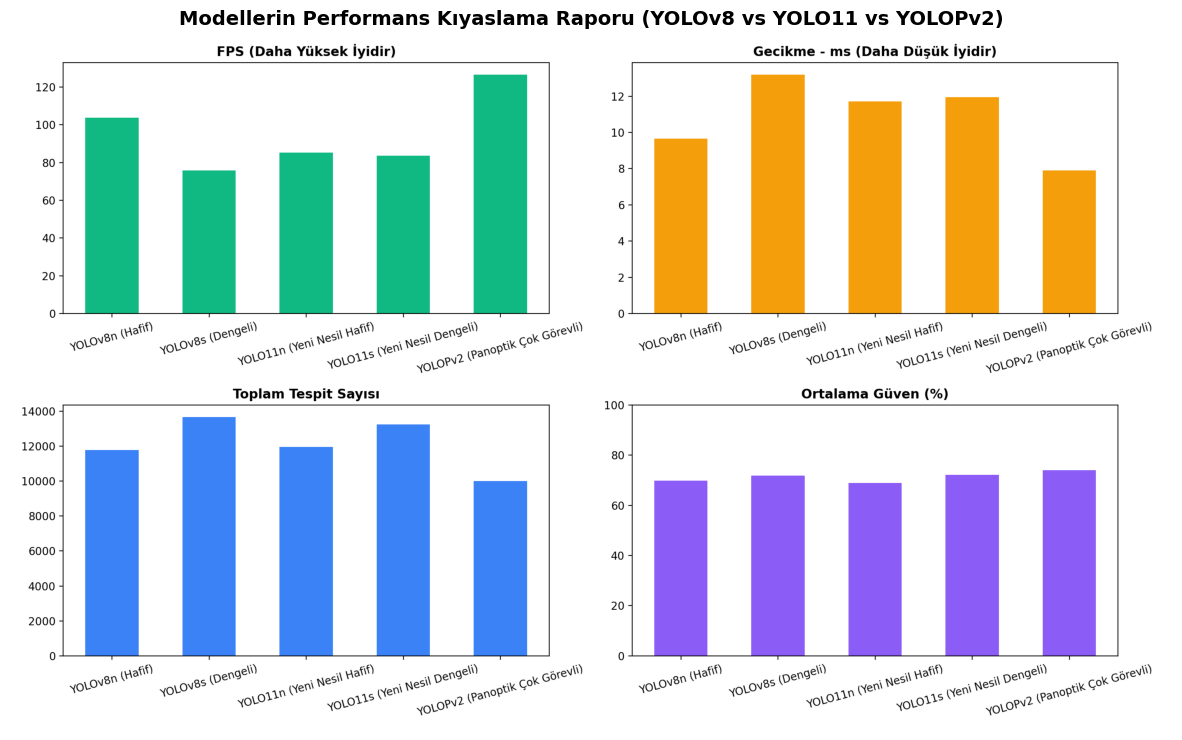

In [ ]:
# Kıyaslanacak modeller (YOLOv8, YOLO11 ve YOLOPv2):
modeller = {
    'YOLOv8n (Hafif)': 'yolov8n.pt',
    'YOLOv8s (Dengeli)': 'yolov8s.pt',
    'YOLO11n (Yeni Nesil Hafif)': 'yolo11n.pt',
    'YOLO11s (Yeni Nesil Dengeli)': 'yolo11s.pt',
    'YOLOPv2 (Panoptik Çok Görevli)': 'yolopv2.pt',
}

# İlk 100 kare üzerinde adil benchmark testi başlat:
benchmark = ADASBenchmark(video_path=VIDEO_PATH, models=modeller, max_benchmark_frames=2000)

if os.path.exists(VIDEO_PATH):
    # Benchmark'ı çalıştır
    sonuclar = benchmark.run_benchmark()

    # 1. Sonuç Tablosunu Yazdır
    benchmark.print_summary_table(sonuclar)

    # 2. Grafik Raporunu Kaydet ve Göster
    benchmark.plot_comparison(sonuclar, output_image='model_karsilastirma.png')

    # Grafiği göster
    plt.figure(figsize=(15, 10))
    plt.imshow(plt.imread('model_karsilastirma.png'))
    plt.axis('off')
    plt.title('Modellerin Performans Kıyaslama Raporu (YOLOv8 vs YOLO11 vs YOLOPv2)', fontsize=14, fontweight='bold')
    plt.show()
else:
    print("Benchmark için lütfen geçerli bir VIDEO_PATH dosyası sağlayın.")


In [ ]:
# 1. demo.py içindeki satırı kesin olarak düzelt (boşluk farkından etkilenmez)
with open('YOLOPv2/demo.py', 'r') as f:
    satirlar = f.readlines()

for i, satir in enumerate(satirlar):
    if 'torch.jit.load' in satir:
        satirlar[i] = "    model = torch.jit.load(weights[0] if isinstance(weights, list) else weights)\n"
        print(f"✅ {i+1}. satırdaki hata düzeltildi!")

with open('YOLOPv2/demo.py', 'w') as f:
    f.writelines(satirlar)

# 2. Şimdi YOLOPv2 videosunu oluştur
!python YOLOPv2/demo.py --source test.mp4 --weights yolopv2.pt --device 0


FileNotFoundError: [Errno 2] No such file or directory: 'YOLOPv2/demo.py'

In [ ]:
import glob
from google.colab import files

# En son üretilen videoyu bul ve indir
videolar = sorted(glob.glob('runs/detect/*/*.mp4'))
if videolar:
    en_son = videolar[-1]
    print(f"📥 İndirilen dosya: {en_son}")
    files.download(en_son)
else:
    print("Video bulunamadı.")


Video bulunamadı.


## 5. 🎬 Seçilen Model ile Nihai Videoyu İşleme ve Kaydetme
Benchmark testinde en yüksek FPS ve doğruluk dengesini sunan modeli seçerek videoyu baştan sona işleyebilirsiniz.


In [ ]:
# En uygun bulduğunuz modeli seçin (örn: yolo11n.pt veya yolov8n.pt)
SECILEN_MODEL = 'yolopv2.pt'
CIKIS_VIDEOSU = 'final_adas_ciktisi.mp4'

if os.path.exists(VIDEO_PATH):
    process_video(
        input_path=VIDEO_PATH,
        output_path=CIKIS_VIDEOSU,
        model_path=SECILEN_MODEL,
        conf_threshold=0.35,
        max_frames=None  # Tüm videoyu işlemek için None bırakın
    )
    print(f"🎉 İşlenmiş video tamamlandı: {CIKIS_VIDEOSU}")

    # Colab'da doğrudan indirmek için:
    # from google.colab import files
    # files.download(CIKIS_VIDEOSU)
else:
    print("İşlem için geçerli bir video bulunamadı.")


/usr/local/lib/python3.13/dist-packages/ultralytics/utils/patches.py:219: UserWarning: 'torch.load' received a zip file that looks like a TorchScript archive dispatching to 'torch.jit.load' (call 'torch.jit.load' directly to silence this warning)
  return torch.load(*args, **kwargs)


TypeError: ERROR ❌️ yolopv2.pt is a TorchScript archive, not an Ultralytics PyTorch checkpoint.
Load the original .pt weights, or export again with format='torchscript' and load that file directly.

## 6. 🖼️ HUD ve Renklendirme Önizlemesi
İşlenen videonun ortasından bir kare alarak şerit, sınıf etiketleri ve mesafe güvenlik kutularını görselleştirin.


In [ ]:
if os.path.exists(VIDEO_PATH):
    cap = cv2.VideoCapture(VIDEO_PATH)
    total_f = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    cap.set(cv2.CAP_PROP_POS_FRAMES, total_f // 2)
    ret, sample_frame = cap.read()
    cap.release()

    if ret:
        h, w = sample_frame.shape[:2]
        test_pipeline = ADASPipeline(w, h, model_path=SECILEN_MODEL)
        preview_frame = test_pipeline.process_frame(sample_frame)

        preview_rgb = cv2.cvtColor(preview_frame, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(15, 8))
        plt.imshow(preview_rgb)
        plt.title('ADAS Sistemi — Örnek Kare Önizlemesi (Mesafe ve Sınıf Renkleri)', fontsize=14, fontweight='bold')
        plt.axis('off')
        plt.show()


TypeError: ERROR ❌️ yolopv2.pt is a TorchScript archive, not an Ultralytics PyTorch checkpoint.
Load the original .pt weights, or export again with format='torchscript' and load that file directly.

In [ ]:
import cv2
import torch
import time
import numpy as np
from ultralytics import YOLO
from google.colab import files

print("🚀 HİBRİT ADAS SİSTEMİ (YOLOPv2 Şerit + YOLO11 Nesne/Mesafe) BAŞLATILIYOR...")

# -------------------------------------------------------------
# 1. MODELLERİ YÜKLE
# -------------------------------------------------------------
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Model A: YOLOPv2 (Derin Öğrenme Şerit Uzmanı)
print("1/2: YOLOPv2 (Şerit ve Yol Segmentasyonu) yükleniyor...")
yolop_model = torch.jit.load('yolopv2.pt').to(device)
if device.type != 'cpu':
    yolop_model.half()
yolop_model.eval()

# Model B: YOLO11 (Trafik Işığı, Yaya ve Araç Dedektörü)
print("2/2: YOLO11s (Nesne ve Mesafe Dedektörü) yükleniyor...")
yolo11_model = YOLO('yolo11s.pt')

# -------------------------------------------------------------
# 2. RENKLER VE GÜVENLİK MESAFESİ AYARLARI
# -------------------------------------------------------------
CLASS_COLORS = {
    0:  {'name': 'Yaya',         'real_h': 1.70, 'color': (0, 230, 255)},    # Parlak Sarı
    1:  {'name': 'Bisiklet',     'real_h': 1.20, 'color': (0, 255, 128)},    # Yeşil
    2:  {'name': 'Araba',        'real_h': 1.50, 'color': (0, 0, 255)},      # Kırmızı
    3:  {'name': 'Motosiklet',   'real_h': 1.30, 'color': (203, 108, 240)},  # Pembe
    5:  {'name': 'Otobus',       'real_h': 3.20, 'color': (0, 165, 255)},    # Turuncu
    7:  {'name': 'Kamyon',       'real_h': 3.50, 'color': (255, 200, 0)},    # Cyan
    9:  {'name': 'Trafik Isigi', 'real_h': 0.85, 'color': (180, 0, 180)},    # Mor
    11: {'name': 'Dur Levhasi',  'real_h': 0.80, 'color': (255, 100, 100)},  # Açık Kırmızı
}

def get_dist_color(dist_m):
    if dist_m < 15.0:
        return (0, 0, 255)     # Yakın: Kırmızı (Tehlike)
    elif dist_m <= 30.0:
        return (0, 140, 255)   # Orta: Turuncu (Uyarı)
    else:
        return (0, 230, 70)    # Uzak: Yeşil (Güvenli)

# -------------------------------------------------------------
# 3. VİDEOYU İŞLE VE KAYDET
# -------------------------------------------------------------
INPUT_VIDEO = VIDEO_PATH      # Giriş videonuz
OUTPUT_VIDEO = "test_hibrit.mp4"  # Kaydedilecek nihai video

cap = cv2.VideoCapture(INPUT_VIDEO)
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

writer = cv2.VideoWriter(OUTPUT_VIDEO, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
focal_length_px = (h / 2.0) / np.tan(np.radians(70.0) / 2.0)

print(f"🎬 Video İşleniyor: {w}x{h} @ {fps:.1f} FPS (Toplam {total_frames} kare)")
start_time = time.time()
frame_idx = 0

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    result_frame = frame.copy()

    # --- 1. Adım: YOLOPv2 ile Şerit ve Sürüş Alanı Çizimi ---
    img_yolop = cv2.resize(frame, (640, 640))
    img_yolop = cv2.cvtColor(img_yolop, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(img_yolop).permute(2, 0, 1).unsqueeze(0).to(device)
    tensor = tensor.half() if device.type != 'cpu' else tensor.float()
    tensor /= 255.0

    with torch.no_grad():
        _, da_seg_out, ll_seg_out = yolop_model(tensor)

    ll_seg_mask = torch.round(ll_seg_out).squeeze(0).squeeze(0).byte().cpu().numpy()
    ll_seg_mask = cv2.resize(ll_seg_mask, (w, h), interpolation=cv2.INTER_NEAREST)

    da_seg_mask = torch.round(da_seg_out[0][1]).byte().cpu().numpy()
    da_seg_mask = cv2.resize(da_seg_mask, (w, h), interpolation=cv2.INTER_NEAREST)

    # Yolu yarı saydam yeşil koridor yap, şeritleri parlak sarı çiz:
    result_frame[da_seg_mask == 1] = (result_frame[da_seg_mask == 1] * 0.7 + np.array([40, 200, 80]) * 0.3).astype(np.uint8)
    result_frame[ll_seg_mask == 1] = [0, 255, 255]

    # --- 2. Adım: YOLO11 ile Işıklar, Yayalar, Araçlar ve Metre Hesabı ---
    yolo_results = yolo11_model.predict(frame, conf=0.35, device=device, verbose=False)

    for box in yolo_results[0].boxes:
        cls_id = int(box.cls[0].item())
        if cls_id not in CLASS_COLORS:
            continue

        cfg = CLASS_COLORS[cls_id]
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        px_h = max(1, y2 - y1)

        # Metre cinsinden mesafe
        dist_m = round((cfg['real_h'] * focal_length_px) / px_h, 1)
        dist_c = get_dist_color(dist_m)
        class_c = cfg['color']

        # Kutu çizgisi (Mesafeye göre kırmızı/turuncu/yeşil)
        cv2.rectangle(result_frame, (x1, y1), (x2, y2), dist_c, 2)

        # Etiket rozeti (Sınıf rengiyle: Trafik ışığı mor, araba kırmızı vb.)
        lbl = f"{cfg['name']} | {dist_m:.1f}m"
        cv2.rectangle(result_frame, (x1, max(0, y1 - 22)), (x1 + len(lbl)*9 + 8, y1), class_c, cv2.FILLED)
        cv2.putText(result_frame, lbl, (x1 + 4, y1 - 6), cv2.FONT_HERSHEY_DUPLEX, 0.45, (255, 255, 255), 1, cv2.LINE_AA)

    # --- 3. Adım: Telemetri Göstergesi ---
    cv2.rectangle(result_frame, (0, 0), (w, 38), (15, 15, 20), cv2.FILLED)
    cv2.putText(result_frame, "HIBRIT ADAS  |  YOLOPv2 (Serit) + YOLO11s (Nesne & Mesafe)", (20, 25), cv2.FONT_HERSHEY_DUPLEX, 0.60, (0, 230, 255), 1, cv2.LINE_AA)

    writer.write(result_frame)
    frame_idx += 1

    if frame_idx % 60 == 0:
        elapsed = time.time() - start_time
        print(f"  [{frame_idx/total_frames*100:5.1f}%] Kare {frame_idx}/{total_frames} | Hız: {frame_idx/elapsed:.1f} FPS")

cap.release()
writer.release()

total_time = time.time() - start_time
print("\n" + "="*50)
print(f"🎉 HİBRİT VİDEO TAMAMLANDI!")
print(f"Toplam Süre: {total_time:.1f} saniye | Ortalama Hız: {frame_idx/total_time:.1f} FPS")
print(f"Kayıt Yeri  : {OUTPUT_VIDEO}")
print("="*50)

# Otomatik İndir
files.download(OUTPUT_VIDEO)


🚀 HİBRİT ADAS SİSTEMİ (YOLOPv2 Şerit + YOLO11 Nesne/Mesafe) BAŞLATILIYOR...
1/2: YOLOPv2 (Şerit ve Yol Segmentasyonu) yükleniyor...
2/2: YOLO11s (Nesne ve Mesafe Dedektörü) yükleniyor...
🎬 Video İşleniyor: 864x496 @ 30.0 FPS (Toplam 3999 kare)
  [  1.5%] Kare 60/3999 | Hız: 15.8 FPS
  [  3.0%] Kare 120/3999 | Hız: 19.1 FPS
  [  4.5%] Kare 180/3999 | Hız: 20.3 FPS
  [  6.0%] Kare 240/3999 | Hız: 21.0 FPS
  [  7.5%] Kare 300/3999 | Hız: 21.5 FPS
  [  9.0%] Kare 360/3999 | Hız: 21.8 FPS
  [ 10.5%] Kare 420/3999 | Hız: 22.0 FPS
  [ 12.0%] Kare 480/3999 | Hız: 22.0 FPS
  [ 13.5%] Kare 540/3999 | Hız: 22.3 FPS
  [ 15.0%] Kare 600/3999 | Hız: 22.5 FPS
  [ 16.5%] Kare 660/3999 | Hız: 22.7 FPS
  [ 18.0%] Kare 720/3999 | Hız: 22.7 FPS
  [ 19.5%] Kare 780/3999 | Hız: 22.7 FPS
  [ 21.0%] Kare 840/3999 | Hız: 22.7 FPS
  [ 22.5%] Kare 900/3999 | Hız: 22.8 FPS
  [ 24.0%] Kare 960/3999 | Hız: 22.9 FPS
  [ 25.5%] Kare 1020/3999 | Hız: 22.9 FPS
  [ 27.0%] Kare 1080/3999 | Hız: 22.9 FPS
  [ 28.5%] Kare 1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>